ANALISIS PERUBAHAN VEGETASI
Lokasi         : -3.25, 102.15
Ukuran area    : 3.0 km
Resolusi       : 20 meter
Ukuran raster  : 150 x 150

TAHUN 2023
Citra ditemukan: 33
Citra digunakan: 5
2023-07-09 | Valid: 100.0%
2023-07-09 | Valid: 100.0%
2023-09-17 | Valid: 98.6%
2023-09-27 | Valid: 90.1%
2023-08-23 | Valid: 70.5%

TAHUN 2025
Citra ditemukan: 20
Citra digunakan: 5
2025-07-18 | Valid: 100.0%
2025-08-22 | Valid: 100.0%
2025-07-03 | Valid: 99.2%
2025-09-26 | Valid: 95.2%
2025-09-18 | Valid: 95.0%

HASIL ANALISIS


,Lokasi,NDVI_2023,NDVI_2025,Delta_NDVI,Luas_Area_ha,Luas_Valid_ha,Cakupan_Valid_Persen,Indikasi_Penurunan_ha,Indikasi_Peningkatan_ha,Penurunan_Persen,Peningkatan_Persen
0,Area kajian Bengkulu Utara,0.5079,0.5498,0.0418,900.0,900.0,100.0,0.2,7.4,0.0222,0.8222


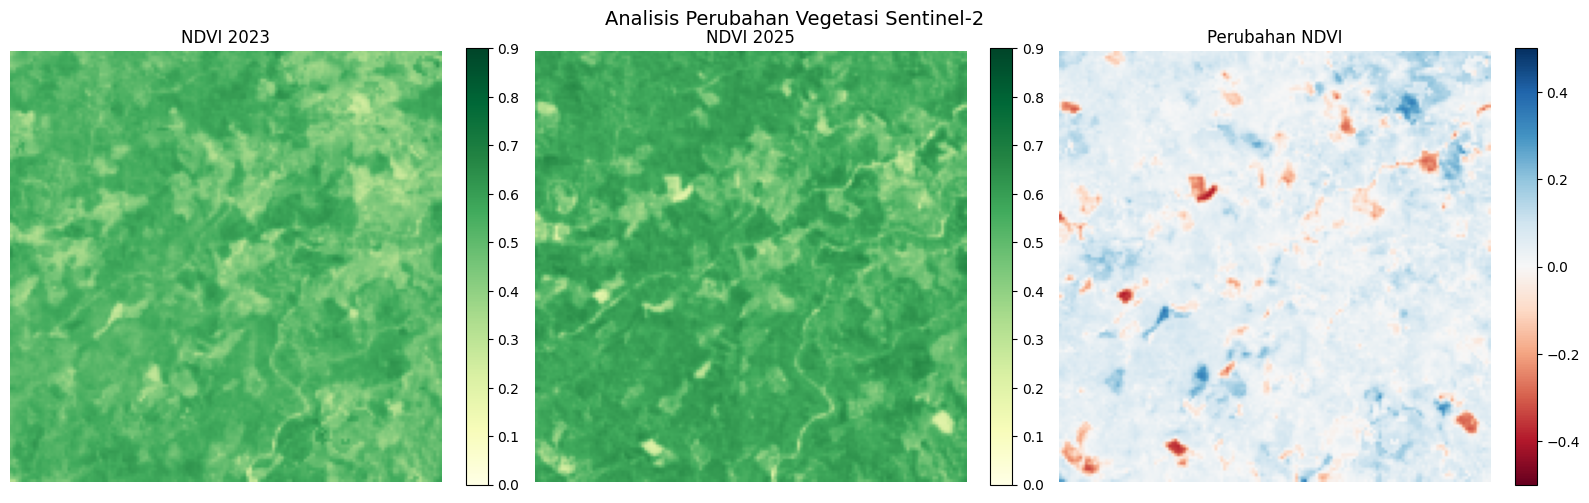

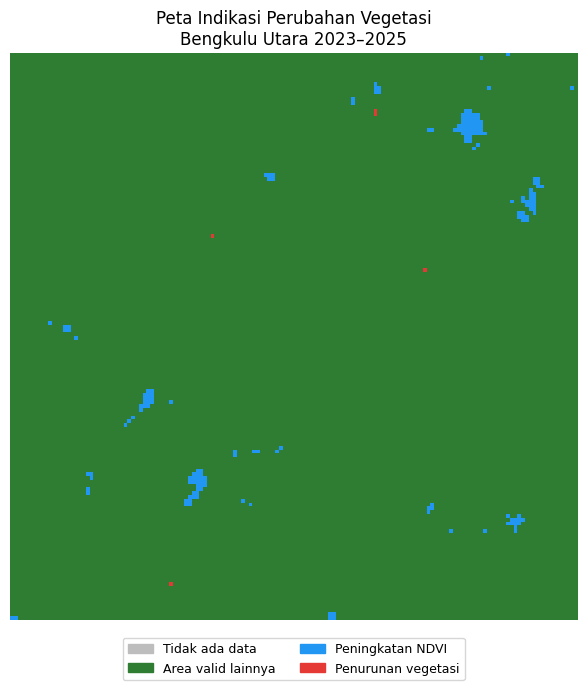

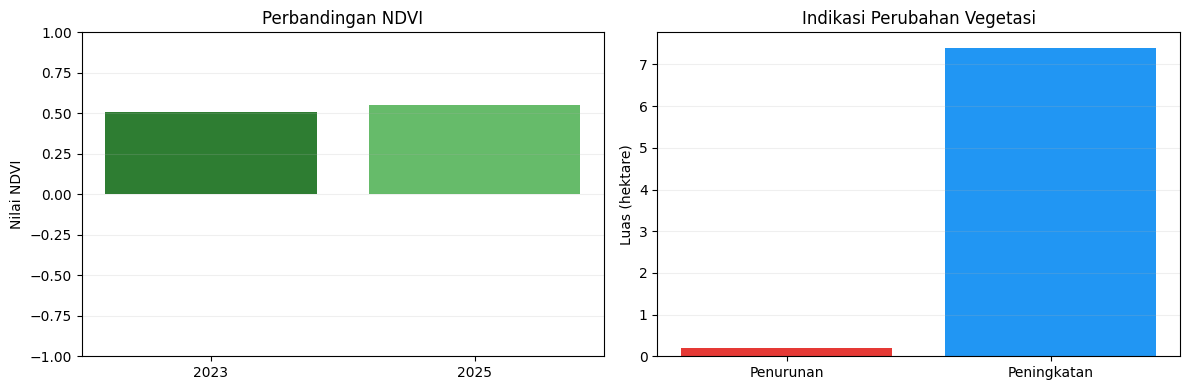


LAPORAN PEMANTAUAN PERUBAHAN VEGETASI
NDVI 2023             : 0.5079
NDVI 2025             : 0.5498
Perubahan NDVI        : 0.0418
Luas area             : 900.00 ha
Luas valid            : 900.00 ha
Cakupan valid         : 100.00%
Indikasi penurunan    : 0.20 ha
Indikasi peningkatan  : 7.40 ha

FILE HASIL
- grafik_statistik.png
- metadata_citra.csv
- perubahan_vegetasi.tif
- peta_ndvi.png
- peta_perubahan.png
- statistik_vegetasi.csv

Analisis selesai.
Hasil merupakan indikasi perubahan vegetasi, bukan konfirmasi penyebab deforestasi.


In [3]:

%pip -q install pystac-client planetary-computer rasterio pyproj pandas matplotlib

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import planetary_computer

from pystac_client import Client
from pyproj import Transformer
from rasterio.crs import CRS
from rasterio.transform import from_origin
from rasterio.enums import Resampling
from rasterio.vrt import WarpedVRT
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ============================================================
# ANALISIS PERUBAHAN VEGETASI MENGGUNAKAN SENTINEL-2
# ============================================================

OUTPUT_DIR = "/content/hasil_pemantauan_hutan"
os.makedirs(OUTPUT_DIR, exist_ok=True)

LATITUDE = -3.25
LONGITUDE = 102.15

AREA_SIZE_M = 3000
RESOLUTION = 20

PERIODS = {
    "2023": "2023-06-01/2023-09-30",
    "2025": "2025-06-01/2025-09-30"
}

MAX_SCENES = 5
MAX_CANDIDATES = 30
MAX_CLOUD_COVER = 80
MIN_VALID_FRACTION = 0.50
MIN_VALID_OBSERVATIONS = 2

NDVI_BASELINE_THRESHOLD = 0.60
NDVI_CHANGE_THRESHOLD = 0.20

# ============================================================
# 1. AREA KAJIAN
# ============================================================

utm_zone = int((LONGITUDE + 180) // 6) + 1
epsg = (32600 if LATITUDE >= 0 else 32700) + utm_zone

dst_crs = CRS.from_epsg(epsg)

to_utm = Transformer.from_crs(
    "EPSG:4326",
    dst_crs,
    always_xy=True
)

center_x, center_y = to_utm.transform(
    LONGITUDE, LATITUDE
)

half_size = AREA_SIZE_M / 2

xmin = center_x - half_size
xmax = center_x + half_size
ymin = center_y - half_size
ymax = center_y + half_size

width = int(np.ceil(AREA_SIZE_M / RESOLUTION))
height = int(np.ceil(AREA_SIZE_M / RESOLUTION))

transform = from_origin(
    xmin,
    ymax,
    RESOLUTION,
    RESOLUTION
)

to_wgs84 = Transformer.from_crs(
    dst_crs,
    "EPSG:4326",
    always_xy=True
)

west, south = to_wgs84.transform(xmin, ymin)
east, north = to_wgs84.transform(xmax, ymax)

bbox = [west, south, east, north]

print("ANALISIS PERUBAHAN VEGETASI")
print(f"Lokasi         : {LATITUDE}, {LONGITUDE}")
print(f"Ukuran area    : {AREA_SIZE_M / 1000:.1f} km")
print(f"Resolusi       : {RESOLUTION} meter")
print(f"Ukuran raster  : {width} x {height}")

# ============================================================
# 2. KONEKSI DATA SATELIT
# ============================================================

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)

def find_scenes(period):
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=period,
        query={
            "eo:cloud_cover": {
                "lt": MAX_CLOUD_COVER
            }
        },
        max_items=150
    )

    items = list(search.items())

    items = list(
        {item.id: item for item in items}.values()
    )

    items.sort(
        key=lambda item: (
            item.properties.get("eo:cloud_cover", 100),
            item.datetime.isoformat()
            if item.datetime else ""
        )
    )

    return items

# ============================================================
# 3. PEMBACAAN BAND SATELIT
# ============================================================

def read_band(item, band_name, categorical=False):
    url = planetary_computer.sign(
        item.assets[band_name].href
    )

    with rasterio.Env(
        GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
        GDAL_HTTP_MAX_RETRY="3",
        GDAL_HTTP_RETRY_DELAY="2"
    ):
        with rasterio.open(url) as src:
            with WarpedVRT(
                src,
                crs=dst_crs,
                transform=transform,
                width=width,
                height=height,
                resampling=(
                    Resampling.nearest
                    if categorical
                    else Resampling.bilinear
                )
            ) as vrt:

                array = vrt.read(
                    1,
                    masked=True
                )

                # Konversi float32 sebelum mengisi NaN.
                array = array.astype(np.float32)

                data = array.filled(np.nan)

    return np.asarray(
        data,
        dtype=np.float32
    )

# ============================================================
# 4. PREPROCESSING DAN NDVI
# ============================================================

def process_scene(item):
    red = read_band(item, "B04")
    nir = read_band(item, "B08")
    scl = read_band(
        item,
        "SCL",
        categorical=True
    )

    valid_scl = np.isin(
        scl,
        [4, 5, 6, 7]
    )

    valid_reflectance = (
        np.isfinite(red)
        & np.isfinite(nir)
        & (red > 0)
        & (nir > 0)
        & (red <= 10000)
        & (nir <= 10000)
    )

    valid = valid_scl & valid_reflectance

    ndvi = np.full(
        (height, width),
        np.nan,
        dtype=np.float32
    )

    denominator = nir + red

    np.divide(
        nir - red,
        denominator,
        out=ndvi,
        where=valid & (denominator > 0)
    )

    ndvi[~valid] = np.nan

    return np.clip(ndvi, -1, 1)

# ============================================================
# 5. KOMPOSIT TEMPORAL
# ============================================================

def create_composite(year, period):
    items = find_scenes(period)

    print(f"\nTAHUN {year}")
    print(f"Citra ditemukan: {len(items)}")

    if not items:
        raise RuntimeError(
            f"Tidak ada citra untuk tahun {year}."
        )

    candidates = items[:MAX_CANDIDATES]

    accepted = []
    records = []

    for item in candidates:
        try:
            ndvi = process_scene(item)

            valid_fraction = float(
                np.isfinite(ndvi).mean()
            )

            record = {
                "year": year,
                "scene_id": item.id,
                "date": (
                    item.datetime.date().isoformat()
                    if item.datetime else ""
                ),
                "cloud_cover_tile": item.properties.get(
                    "eo:cloud_cover", np.nan
                ),
                "valid_fraction_aoi": valid_fraction
            }

            records.append(record)

            if valid_fraction >= MIN_VALID_FRACTION:
                accepted.append({
                    "item": item,
                    "ndvi": ndvi,
                    "coverage": valid_fraction
                })

        except Exception as error:
            print(
                f"Citra dilewati: {item.id} | "
                f"{str(error)[:100]}"
            )

    if len(accepted) < MIN_VALID_OBSERVATIONS:
        raise RuntimeError(
            f"Citra valid untuk {year} tidak mencukupi. "
            "Perluas periode pengamatan."
        )

    accepted.sort(
        key=lambda entry: entry["coverage"],
        reverse=True
    )

    selected = accepted[:MAX_SCENES]

    stack = np.stack(
        [entry["ndvi"] for entry in selected],
        axis=0
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        composite = np.nanmedian(stack, axis=0)

    observations = np.sum(
        np.isfinite(stack),
        axis=0
    )

    composite[
        observations < MIN_VALID_OBSERVATIONS
    ] = np.nan

    print(f"Citra digunakan: {len(selected)}")

    selected_ids = set()

    for entry in selected:
        item = entry["item"]
        selected_ids.add(item.id)

        print(
            f"{item.datetime.date()} | "
            f"Valid: {entry['coverage'] * 100:.1f}%"
        )

    for record in records:
        record["selected"] = (
            record["scene_id"] in selected_ids
        )

    return composite, observations, records

# ============================================================
# 6. PEMROSESAN MULTITEMPORAL
# ============================================================

ndvi_2023, obs_2023, records_2023 = create_composite(
    "2023", PERIODS["2023"]
)

ndvi_2025, obs_2025, records_2025 = create_composite(
    "2025", PERIODS["2025"]
)

valid_mask = (
    np.isfinite(ndvi_2023)
    & np.isfinite(ndvi_2025)
)

if not np.any(valid_mask):
    raise RuntimeError(
        "Tidak ada piksel valid pada kedua periode."
    )

delta_ndvi = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

delta_ndvi[valid_mask] = (
    ndvi_2025[valid_mask]
    - ndvi_2023[valid_mask]
)

# ============================================================
# 7. DETEKSI PERUBAHAN VEGETASI
# ============================================================

vegetation_loss = (
    valid_mask
    & (ndvi_2023 >= NDVI_BASELINE_THRESHOLD)
    & (delta_ndvi <= -NDVI_CHANGE_THRESHOLD)
)

vegetation_gain = (
    valid_mask
    & (delta_ndvi >= NDVI_CHANGE_THRESHOLD)
)

classification = np.zeros(
    (height, width),
    dtype=np.uint8
)

classification[valid_mask] = 1
classification[vegetation_gain] = 2
classification[vegetation_loss] = 3

# ============================================================
# 8. STATISTIK PERUBAHAN
# ============================================================

pixel_area_ha = RESOLUTION**2 / 10000

area_total = height * width * pixel_area_ha
area_valid = np.count_nonzero(valid_mask) * pixel_area_ha
area_loss = np.count_nonzero(vegetation_loss) * pixel_area_ha
area_gain = np.count_nonzero(vegetation_gain) * pixel_area_ha

mean_2023 = float(
    np.mean(ndvi_2023[valid_mask])
)

mean_2025 = float(
    np.mean(ndvi_2025[valid_mask])
)

mean_change = mean_2025 - mean_2023
coverage = area_valid / area_total * 100

summary = pd.DataFrame([{
    "Lokasi": "Area kajian Bengkulu Utara",
    "NDVI_2023": mean_2023,
    "NDVI_2025": mean_2025,
    "Delta_NDVI": mean_change,
    "Luas_Area_ha": area_total,
    "Luas_Valid_ha": area_valid,
    "Cakupan_Valid_Persen": coverage,
    "Indikasi_Penurunan_ha": area_loss,
    "Indikasi_Peningkatan_ha": area_gain,
    "Penurunan_Persen": area_loss / area_valid * 100,
    "Peningkatan_Persen": area_gain / area_valid * 100
}])

print("\nHASIL ANALISIS")
display(summary.round(4))

if coverage < 70:
    print(
        "PERINGATAN: Cakupan data valid kurang dari 70%."
    )

# ============================================================
# 9. VISUALISASI NDVI
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

datasets = [
    (ndvi_2023, "NDVI 2023", "YlGn", 0, 0.9),
    (ndvi_2025, "NDVI 2025", "YlGn", 0, 0.9),
    (delta_ndvi, "Perubahan NDVI", "RdBu", -0.5, 0.5)
]

for ax, (data, title, cmap, vmin, vmax) in zip(
    axes, datasets
):
    im = ax.imshow(
        data,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title)
    ax.axis("off")

    plt.colorbar(
        im,
        ax=ax,
        fraction=0.046
    )

plt.suptitle(
    "Analisis Perubahan Vegetasi Sentinel-2",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/peta_ndvi.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 10. PETA KLASIFIKASI PERUBAHAN
# ============================================================

cmap = ListedColormap([
    "#BDBDBD",
    "#2E7D32",
    "#2196F3",
    "#E53935"
])

fig, ax = plt.subplots(figsize=(8, 7))

ax.imshow(
    classification,
    cmap=cmap,
    vmin=0,
    vmax=3,
    interpolation="nearest"
)

ax.set_title(
    "Peta Indikasi Perubahan Vegetasi\n"
    "Bengkulu Utara 2023–2025"
)

ax.axis("off")

legend_items = [
    Patch(color="#BDBDBD", label="Tidak ada data"),
    Patch(color="#2E7D32", label="Area valid lainnya"),
    Patch(color="#2196F3", label="Peningkatan NDVI"),
    Patch(color="#E53935", label="Penurunan vegetasi")
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/peta_perubahan.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. GRAFIK STATISTIK
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    ["2023", "2025"],
    [mean_2023, mean_2025],
    color=["#2E7D32", "#66BB6A"]
)

axes[0].set_title("Perbandingan NDVI")
axes[0].set_ylabel("Nilai NDVI")
axes[0].set_ylim(-1, 1)
axes[0].grid(axis="y", alpha=0.2)

axes[1].bar(
    ["Penurunan", "Peningkatan"],
    [area_loss, area_gain],
    color=["#E53935", "#2196F3"]
)

axes[1].set_title("Indikasi Perubahan Vegetasi")
axes[1].set_ylabel("Luas (hektare)")
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/grafik_statistik.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. EKSPOR CSV
# ============================================================

summary.to_csv(
    f"{OUTPUT_DIR}/statistik_vegetasi.csv",
    index=False
)

metadata = pd.DataFrame(
    records_2023 + records_2025
)

metadata.to_csv(
    f"{OUTPUT_DIR}/metadata_citra.csv",
    index=False
)

# ============================================================
# 13. EKSPOR GEOTIFF
# ============================================================

tif_path = f"{OUTPUT_DIR}/perubahan_vegetasi.tif"

raster_bands = [
    ndvi_2023,
    ndvi_2025,
    delta_ndvi,
    np.where(
        valid_mask,
        vegetation_loss.astype(np.float32),
        np.nan
    )
]

descriptions = [
    "NDVI_2023",
    "NDVI_2025",
    "Delta_NDVI",
    "Indikasi_Penurunan"
]

with rasterio.open(
    tif_path,
    "w",
    driver="GTiff",
    height=height,
    width=width,
    count=len(raster_bands),
    dtype="float32",
    crs=dst_crs,
    transform=transform,
    nodata=-9999,
    compress="deflate"
) as dst:

    for i, (band, description) in enumerate(
        zip(raster_bands, descriptions),
        start=1
    ):
        dst.write(
            np.where(
                np.isfinite(band),
                band,
                -9999
            ).astype(np.float32),
            i
        )

        dst.set_band_description(i, description)

# ============================================================
# 14. LAPORAN AKHIR
# ============================================================

print("\n" + "=" * 55)
print("LAPORAN PEMANTAUAN PERUBAHAN VEGETASI")
print("=" * 55)

print(f"NDVI 2023             : {mean_2023:.4f}")
print(f"NDVI 2025             : {mean_2025:.4f}")
print(f"Perubahan NDVI        : {mean_change:.4f}")
print(f"Luas area             : {area_total:.2f} ha")
print(f"Luas valid            : {area_valid:.2f} ha")
print(f"Cakupan valid         : {coverage:.2f}%")
print(f"Indikasi penurunan    : {area_loss:.2f} ha")
print(f"Indikasi peningkatan  : {area_gain:.2f} ha")

print("\nFILE HASIL")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

print("\nAnalisis selesai.")
print(
    "Hasil merupakan indikasi perubahan vegetasi, "
    "bukan konfirmasi penyebab deforestasi."
)
